# <font color="blue"><b>From Instruction Fine-Tuning to QLoRA: A Cost–Quality Study on Financial Instruction Tuning</b></font>

---

## Problem Statement

Large language models are expensive to adapt. **Full fine-tuning** updates every weight in the model — it works well but needs a lot of GPU memory and compute, which puts it out of reach on modest hardware. Two parameter-efficient methods promise most of the quality for a fraction of the cost:

- **LoRA** freezes the model and trains only small low-rank adapter matrices (a small fraction of the parameters; the fraction depends on rank and target modules).
- **QLoRA** goes further — it stores the frozen model in **4-bit**, then trains the same LoRA adapters on top, cutting memory again.

In this assignment you will put these three methods on a real task: teaching **Qwen2.5-0.5B-Instruct** to answer financial and general instructions from the **Finance Alpaca (`gbharti/finance-alpaca`)** dataset (each example is `instruction (+ optional input) → output`). You will fine-tune the **same model on the same data three ways**, then measure what each approach costs and what it buys.

**The central question:** *given a fixed model, a fixed dataset, and a single free T4 GPU, is it worth updating all ~500M parameters — or does a low-rank slice (LoRA), or a low-rank slice over a 4-bit backbone (QLoRA), get you almost the same answer quality for far less memory?* You will also compare **two LoRA ranks (r = 8 and r = 16)** for both LoRA and QLoRA, to see how adapter capacity trades against cost.

---

## What You Will Do

You will build the pipeline end-to-end, as a hand-written training loop (a torch `Dataset`, a `collate` function, and `DataLoader`s — no `Trainer`), reused across all three methods:

1. **Imports & seed** — set up the environment reproducibly. *(provided)*
2. **Configuration** — model, data sizes, and all hyperparameters in one place. *(provided)*
3. **Helper functions** — LoRA/QLoRA configs, parameter counting, memory utilities. *(provided)*
4. **Load dataset + statistics** — take 300 / 30 / 30 for train / val / test; inspect fields and lengths.
5. **Dataset, collate & loaders** — build the prompt with the chat template, mark answer tokens with an offset-based mask, pad batches, and create the three loaders.
6. **Model load + IFT training** — write the masked-loss + shared training loop, then run **full instruction fine-tuning**.
7. **LoRA** — freeze the backbone and train adapters at **r = 8 and r = 16**.
8. **QLoRA** — repeat the rank sweep with a **4-bit NF4** backbone.
9. **Test evaluation** — greedy-generate on the test set and score every run with **ROUGE-L** and **BERTScore-F1**.
10. **Plots** — per-epoch train vs validation loss for every run.
11. **Error analysis** — inspect the best model's answers vs the references and summarise the failure modes.
12. **Parameter analysis** — compare quality against % trainable parameters, peak memory, and training time.

**How the notebook is organised**
- Cells marked **`# ── PROVIDED ──`** are already written — just run them in order.
- You only need to write the code inside **`## CODE HERE ##`**.
- Every step with a red **`[marks]`** tag is graded: complete the code where indicated and write the **`Your Answer`** reflection.
- Reflections must **cite the actual numbers your run produced** — not generic descriptions.

**Runtime target:** Colab **T4 GPU**. Use a small subset and short runs; session duration and memory depend on the installed software and runtime. Select a GPU and run top-to-bottom after a restart. No API key needed. Checkpoints are saved locally so only one run occupies GPU memory at a time.

> **Scope.** This is an educational instruction-tuning experiment. Similarity to a reference does not verify financial calculations, current regulations, or suitability of advice.

---

## Mark Distribution

| Step | Topic | Marks |
|------|-------|-------|
| 1 | Imports & seed | 0 *(provided)* |
| 2 | Configuration | 0 *(provided)* |
| 3 | Helper functions (LoRA / QLoRA) | 0 *(provided)* |
| 4 | Load dataset + statistics | 8 |
| 5 | Dataset, collate & loaders | 14 |
| 6 | Model load + IFT training | 20 |
| 7 | LoRA (r = 8 and r = 16) | 14 |
| 8 | QLoRA (r = 8 and r = 16) | 14 |
| 9 | Test evaluation (ROUGE-L + BERTScore) | 10 |
| 10 | Plots (train vs validation) | 6 |
| 11 | Error analysis | 8 |
| 12 | Parameter analysis | 6 |
| | **Total** | **100** |

Most marks sit where the core learning is: the training loop and full IFT (Step 6), and the data pipeline plus the two PEFT methods (Steps 5, 7, 8). Steps 1–3 are provided scaffolding and carry no marks.

---
**Dataset setting:** use the full mixed-domain Finance Alpaca dataset as requested. The dataset card describes a combination of Stanford Alpaca, FiQA, and approximately 1.3k custom GPT-3.5-generated pairs. It is not a finance-only benchmark; random-sample results reflect the mixed dataset. No topic filter is applied because the dataset does not provide reliable row-level topic/source labels.

**Dataset source:** [Finance Alpaca dataset card](https://huggingface.co/datasets/gbharti/finance-alpaca) and [requested viewer](https://huggingface.co/datasets/gbharti/finance-alpaca/viewer/default/train?row=0). Use `instruction`, `input`, and `output`; ignore the unused `text` column. References have mixed provenance and should not be treated as uniformly machine-generated or expert-verified.

**Length policy:** reserve 64 tokens of the training budget for answer content. Step 5 trims an overlong user message to fit the prompt budget, preserving the chat structure; the same prompt construction is used at evaluation. Long answers are right-truncated during training without inserting an artificial EOS. Inspect the reported truncation counts and discuss the information lost.

**Results:** run all five experiments before completing the reflection templates. No scores from an earlier dataset are retained.


In [2]:
# Install the training and evaluation dependencies in a fresh Colab runtime.
!pip install -q "transformers>=4.45,<5" "datasets>=2.20,<4" "peft>=0.13,<1" "accelerate>=0.34,<2" "bitsandbytes>=0.43,<1" evaluate rouge_score bert_score


In [3]:
# Avoid a torchao/T4 incompatibility that can surface with peft/quantised stacks.
!pip uninstall -y -q torchao

### <font color="blue"><b>Step 1: Imports and Seed Setting</b></font>  *(provided — just run)*

Import the libraries used throughout — PyTorch and `torch.utils.data`, Hugging Face `transformers` / `datasets` / `peft`, and plotting — and fix a single random seed across `random`, NumPy, and PyTorch (`seed_everything`) so every run is reproducible.

> `# ── PROVIDED ──` This cell is written for you. Run it and move on.

In [4]:
# ============================================================
# 1. Imports and Seed Setting
# ---PROVIDED ------------------------------------------------
# ============================================================
import os, gc, math, time, random, warnings, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForCausalLM,
                          BitsAndBytesConfig, get_cosine_schedule_with_warmup,
                          set_seed)
from peft import (LoraConfig, get_peft_model, prepare_model_for_kbit_training,
                  TaskType)

warnings.filterwarnings("ignore")

SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    set_seed(seed)

seed_everything()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
from peft import PeftModel


Device: cuda
GPU: Tesla T4


### <font color="blue"><b>Step 2: Configuration</b></font>  *(provided — just run)*

All the knobs in one place: the model ID, dataset split sizes (`N_TRAIN` / `N_VAL` / `N_TEST`), the sequence-length budget (`MAX_LEN`), and the training hyperparameters — batch size, gradient accumulation, epochs, the two learning rates (`LR_FULL`, `LR_LORA`), and the LoRA ranks. The rest of the notebook reads from these constants, so change behaviour here rather than editing later cells.

> `# ── PROVIDED ──` This cell is written for you. Run it and move on.

In [5]:
# ============================================================
#  Step 2: Configuration
# ---PROVIDED ------------------------------------------------
# ============================================================
MODEL_ID   = "Qwen/Qwen2.5-0.5B-Instruct"

# ---- Data ----
DATASET_ID = "gbharti/finance-alpaca"
CHECKPOINT_DIR = "finance_alpaca_checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
N_TRAIN    = 300
N_VAL      = 30
N_TEST     = 30
MAX_LEN    = 256        # token budget per (prompt + answer) example
ANSWER_RESERVE = 64    # minimum answer-space budget when trimming long prompts

# ---- Training ----
BATCH_SIZE = 4          # small: fits a free T4 - if not fit please reduce it
GRAD_ACCUM = 1          # effective batch = BATCH_SIZE * GRAD_ACCUM
EPOCHS     = 3
WARMUP_RATIO  = 0.05
MAX_GRAD_NORM = 1.0

LR_FULL    = 1e-5       # full fine-tuning: small LR (all weights move)
LR_LORA    = 2e-4       # LoRA / QLoRA: frozen backbone -> larger LR is safe

# ---- LoRA / QLoRA ----
LORA_R       = 16
LORA_ALPHA   = 32
LORA_DROPOUT = 0.05

# ---- Evaluation ----
EVAL_N     = N_TEST         # number of test prompts to generate on when scoring

### <font color="blue"><b>Step 3: Helper Functions</b></font>  *(provided — just run)*

Small utilities reused across every method: `count_trainable` (trainable-vs-total parameter counts), `get_lora_config` / `get_bnb_config` (the shared LoRA and 4-bit NF4 quantisation settings), and `gpu_mem_gb` / `free_memory` (peak-memory reporting and VRAM cleanup between runs).

> `# ── PROVIDED ──` This cell is written for you. Run it and move on.

In [6]:
# ============================================================
#  Step 3: Helper Functions (LoRA / QLoRA)
# ---PROVIDED ------------------------------------------------
# ============================================================

def count_trainable(model):
    """Return (trainable, total, percent-trainable) parameter counts."""
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total     = sum(p.numel() for p in model.parameters())
    return trainable, total, 100 * trainable / total


def get_lora_config():
    """Standard LoRA config for Qwen2.5 (attention + MLP projections)."""
    return LoraConfig(
        task_type=TaskType.CAUSAL_LM,
        r=LORA_R,
        lora_alpha=LORA_ALPHA,
        lora_dropout=LORA_DROPOUT,
        bias="none",
        target_modules=["q_proj", "k_proj", "v_proj", "o_proj",
                        "gate_proj", "up_proj", "down_proj"],
    )


def get_bnb_config():
    """4-bit NF4 quantisation config for QLoRA (fp16 compute for T4)."""
    return BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=torch.float16,
    )


def gpu_mem_gb():
    """Peak GPU memory used since the last reset, in GB."""
    return torch.cuda.max_memory_allocated() / 1e9 if torch.cuda.is_available() else 0.0


def free_memory(*objs):
    """Collect unused objects and clear the cache; delete caller references first."""
    for o in objs:
        try: del o
        except Exception: pass
    gc.collect()
    torch.cuda.empty_cache()
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()

## <font color="blue"><b>Step 4: Load Finance Alpaca and Statistics</b></font> <font color="red">**[8 marks]**</font>

Load `gbharti/finance-alpaca`, split `train`. Keep `instruction` (task/question), `input` (optional context), and `output` (reference answer). Ignore the unused `text` column. Fill missing context with an empty string; do not erase actual financial input. Remove missing/blank instructions or answers, then deduplicate normalized **instruction + input pairs** before splitting.

Shuffle with the fixed seed and select **300 train / 30 validation / 30 test**. Print the fraction of non-empty inputs and token-length statistics (mean, median, p95, max), plus a histogram. This is a mixed-domain dataset, so report performance as Finance Alpaca instruction tuning rather than finance-only performance. Random splits may still share related paraphrases.

**Marks:** code **[4 marks]** — correct loading, cleaning, disjoint splits, statistics and histogram; reflection **[4 marks]** — see below.


README.md:   0%|          | 0.00/831 [00:00<?, ?B/s]

Cleaned_date.json:   0%|          | 0.00/42.9M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/68912 [00:00<?, ? examples/s]

Training samples  : 300
Validation samples: 30
Test samples      : 30


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Rows with extra input : 36.7%
Token length  mean=92  median=66  p95=216  max=1109

----- Sample Training Example -----
Instruction: Generate an interesting random fact.
Input      : 
Output     : Bioluminescent sea creatures produce light using a chemical reaction involving luciferin, an enzyme called luciferase, and oxygen.
-----------------------------------


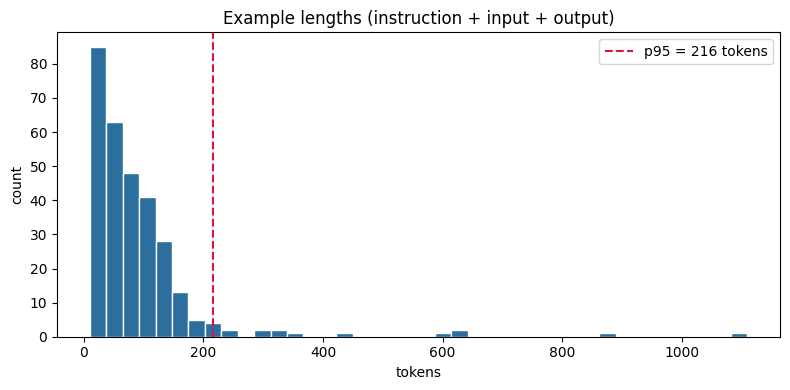

In [7]:
# ============================================================
#  Step 4: Load Dataset and Statistics
# ============================================================

raw = load_dataset(DATASET_ID, split="train")
df = raw.to_pandas()
required = {"instruction", "input", "output"}
assert required.issubset(df.columns), f"Unexpected schema: {list(df.columns)}"
df = df[["instruction", "input", "output"]].copy()
df = df.dropna(subset=["instruction", "output"])
df["input"] = df["input"].fillna("")
for col in ["instruction", "input", "output"]:
    df[col] = df[col].astype(str).str.strip()
df = df[(df["instruction"] != "") & (df["output"] != "")].copy()
# Deduplicate the actual user prompt, including any context.
normalized = lambda col: df[col].str.casefold().str.replace(r"\s+", " ", regex=True)
df["_prompt_key"] = list(zip(normalized("instruction"), normalized("input")))
df = df.drop_duplicates("_prompt_key")
assert len(df) >= N_TRAIN + N_VAL + N_TEST

# Shuffle once, then slice off the splits by index.
df = df.sample(frac=1.0, random_state=SEED).reset_index(drop=True)

train_df = df.iloc[:N_TRAIN].copy()

val_df = df.iloc[
    N_TRAIN:N_TRAIN + N_VAL
].copy()

test_df = df.iloc[
    N_TRAIN + N_VAL:N_TRAIN + N_VAL + N_TEST
].copy()

print("Training samples  :", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples      :", len(test_df))



keys = [set(frame["_prompt_key"]) for frame in [train_df, val_df, test_df]]
assert not (keys[0] & keys[1] or keys[0] & keys[2] or keys[1] & keys[2])

# ---- Basic statistics on the training split ----
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

frac_with_input = (train_df["input"] != "").mean()

def combined_len(r):
    combined_text = (
        str(r["instruction"]) + "\n" +
        str(r["input"]) + "\n" +
        str(r["output"])
    )

    return len(
        tokenizer.encode(
            combined_text,
            add_special_tokens=False
        )
    )


lens = train_df.apply(combined_len, axis=1).values
print(f"Rows with extra input : {frac_with_input:.1%}")
print(f"Token length  mean={lens.mean():.0f}  median={np.median(lens):.0f}  "
      f"p95={np.percentile(lens,95):.0f}  max={lens.max()}")

# Show one example so the format is concrete.


example = train_df.iloc[0]

print("\n----- Sample Training Example -----")
print("Instruction:", example["instruction"])
print("Input      :", example["input"])
print("Output     :", example["output"])
print("-----------------------------------")


plt.figure(figsize=(8, 4))
plt.hist(lens, bins=40, color="#2c6e9e", edgecolor="white")
plt.axvline(np.percentile(lens, 95), color="crimson", ls="--",
            label=f"p95 = {np.percentile(lens,95):.0f} tokens")
plt.title("Example lengths (instruction + input + output)")
plt.xlabel("tokens"); plt.ylabel("count"); plt.legend()
plt.tight_layout(); plt.show()

### ✍️ Step 4 Reflection <font color="red">[4 marks]</font>

**[Your Answer]** must cover:
- Explain `instruction`, optional `input`, and `output`; report the observed non-empty-input fraction. **[1 mark]**
- Report mean / median / p95 / max token lengths and justify `MAX_LEN` against the distribution and GPU budget. **[2 marks]**
- Explain the mixed domains and reference provenance, and why agreement with these answers does not establish financial correctness. **[1 mark]**

*Cite the actual numbers your Finance Alpaca run produced.*


<font color="green">ANSWER:
1) The instruction contains the task or question, input provides optional context, and output is the expected response. In my training dataset, 36.7% of samples had non-empty inputs.

2) The mean token length was 92, median 66, p95 216, and maximum 1,109. I used MAX_LEN = 256 because it accommodates most examples while keeping GPU memory usage manageable on the T4. However, longer examples may be truncated, resulting in some information loss.

3) Finance Alpaca contains both financial and general instructions from Stanford Alpaca, FiQA, and GPT-3.5-generated examples. Since the reference answers are not uniformly expert-verified, higher similarity scores do not guarantee financial accuracy, correctness of calculations, or reliable financial advice.
---------------------
---------------------
---------------------
</font>

## <font color="blue"><b>Step 5: Dataset, Collate, and DataLoaders</b></font>  <font color="red">**[14 marks]**</font>

Build the input pipeline as a hand-written `torch.utils.data.Dataset` (like the DPO demo), with tokenisation deferred to a `collate` function:

- **`build_prompt`** — renders the instruction plus optional context and trims overlong user content to reserve `ANSWER_RESERVE` tokens. Apply the same policy for training and generation.
- **`SFTDataset`** — holds `(prompt, answer)` text pairs. The prompt is rendered with the tokenizer's **chat template** (instruction → *user* turn, primed to answer).
- **`tokenize_example`** — tokenises the full `prompt + answer` **once** and uses the **offset mapping** to mark exactly where the answer begins, producing a `comp_mask` (1 = answer token, 0 = prompt token).
- **`collate`** — pads a batch to its longest sequence and returns `input_ids`, `attn`, and `comp_mask`.
- **Three DataLoaders** — `train_loader` (shuffled), `val_loader`, `test_loader`.

Finally, print the **first full training batch** to confirm the shapes and the answer/prompt masking.

**Marks:** code <font color="red">**[10 marks]**</font> — `SFTDataset` + chat-template prompt, offset-based `comp_mask`, correct padded `collate`, three loaders, and the batch print; reflection <font color="red">**[4 marks]**</font> — see below.

In [8]:
# ============================================================
#  Step 5: Dataset, Collate, and DataLoaders
# ============================================================

SYSTEM_MSG = (
    "You are a helpful assistant for financial and general questions. "
    "Use the supplied context, explain calculations and assumptions clearly, "
    "and state when information is insufficient. Do not invent facts or guarantee returns."
)
PROMPT_STATS = {"calls": 0, "trimmed": 0}

def build_prompt(instruction, input_text):

    PROMPT_STATS["calls"] += 1

    instruction = str(instruction).strip()
    input_text = str(input_text).strip()

    user_text = instruction
    if input_text:
        user_text += "\n\nContext:\n" + input_text

    def render(content):
        messages = [
            {"role": "system", "content": SYSTEM_MSG},
            {"role": "user", "content": content}
        ]
        return tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True
        )

    prompt = render(user_text)
    prompt_budget = MAX_LEN - ANSWER_RESERVE

    def token_length(text):
        return len(tokenizer(
            text, add_special_tokens=False
        )["input_ids"])

    if token_length(prompt) > prompt_budget:
        PROMPT_STATS["trimmed"] += 1

        content_ids = tokenizer(
            user_text, add_special_tokens=False
        )["input_ids"]

        overhead = token_length(render(""))
        budget = max(0, prompt_budget - overhead)

        content_ids = content_ids[:budget]

        while True:
            trimmed_text = tokenizer.decode(
                content_ids,
                skip_special_tokens=True
            )
            prompt = render(trimmed_text)

            if token_length(prompt) <= prompt_budget:
                break

            if not content_ids:
                raise ValueError(
                    "Chat template exceeds prompt budget."
                )

            content_ids = content_ids[:-1]

    return prompt




class SFTDataset(Dataset):
    """Holds (prompt_text, answer_text) pairs; tokenisation is deferred to collate()."""

    def __init__(self, dataframe):
        self.examples = []

        for _, row in dataframe.iterrows():
            prompt = build_prompt(
                row["instruction"], row["input"]
            )
            answer = str(row["output"]).strip()

            self.examples.append((prompt, answer))

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, idx):
        return self.examples[idx]




def tokenize_example(prompt, answer):
    """
    Tokenise the full (prompt + answer) once and use the offset mapping to mark
    exactly where the answer begins. comp_mask = 1 on answer tokens, 0 on prompt.
    Tokenising once avoids token-merge drift at the boundary.
    """

    eos = tokenizer.eos_token or ""
    full_text = prompt + answer

    # Append EOS only when the complete answer fits.
    complete_ids = tokenizer(
        full_text,
        add_special_tokens=False
    )["input_ids"]

    if len(complete_ids) < MAX_LEN:
        full_text += eos

    encoded = tokenizer(
        full_text,
        add_special_tokens=False,
        truncation=True,
        max_length=MAX_LEN,
        return_offsets_mapping=True
    )

    input_ids = encoded["input_ids"]
    offsets = encoded["offset_mapping"]

    answer_start = len(prompt)

    comp_mask = [
        1 if start >= answer_start and end > start else 0
        for start, end in offsets
    ]

    # EOS can have a zero-length offset in some tokenizers.
    # Supervise it when it was intentionally appended.
    if full_text.endswith(eos) and eos:
        if input_ids and input_ids[-1] == tokenizer.eos_token_id:
            comp_mask[-1] = 1

    assert len(input_ids) == len(comp_mask)

    return input_ids, comp_mask


def collate(batch):
    """Pad a batch to its longest sequence. Returns input_ids, attn, comp_mask."""

    examples = [
        tokenize_example(prompt, answer)
        for prompt, answer in batch
    ]

    max_len = max(len(ids) for ids, mask in examples)

    all_ids = []
    all_attn = []
    all_masks = []

    for ids, mask in examples:
        pad_len = max_len - len(ids)

        all_ids.append(
            ids + [tokenizer.pad_token_id] * pad_len
        )
        all_attn.append(
            [1] * len(ids) + [0] * pad_len
        )
        all_masks.append(
            mask + [0] * pad_len
        )

    input_ids = torch.tensor(all_ids, dtype=torch.long)
    attn = torch.tensor(all_attn, dtype=torch.long)
    comp_mask = torch.tensor(all_masks, dtype=torch.long)

    return input_ids, attn, comp_mask



# ---- Three DataLoaders ----

train_dataset = SFTDataset(train_df)
val_dataset = SFTDataset(val_df)
test_dataset = SFTDataset(test_df)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate
)


print("Prompt construction across train/val/test:", dict(PROMPT_STATS))
print(f"Train batches : {len(train_loader)}")
print(f"Val batches   : {len(val_loader)}")
print(f"Test batches  : {len(test_loader)}")

# ---- Print the first batch of the train loader ----
# ---- Print the first FULL batch of the train loader ----
input_ids, attn, comp_mask = next(iter(train_loader))
print("=== First training batch (full) ===")
print("input_ids shape :", tuple(input_ids.shape))
print("attn shape      :", tuple(attn.shape))
print("comp_mask shape :", tuple(comp_mask.shape))
print("Answer tokens (supervised):", int(comp_mask.sum()))

torch.set_printoptions(profile="full")   # don't truncate the tensors

print("\ninput_ids:\n", input_ids)
print("\nattn:\n", attn)
print("\ncomp_mask:\n", comp_mask)

torch.set_printoptions(profile="default")   # restore normal printing
# Inspect the actual chat-formatted training lengths and truncation rate.
formatted_lens = np.array([
    len(tokenizer(build_prompt(r["instruction"], r["input"]) + r["output"],
                  add_special_tokens=False)["input_ids"]) + 1
    for _, r in train_df.iterrows()
])
print("Formatted length mean / median / p95 / max:",
      formatted_lens.mean(), np.median(formatted_lens),
      np.percentile(formatted_lens, 95), formatted_lens.max())
print(f"Training examples exceeding MAX_LEN: {(formatted_lens > MAX_LEN).mean():.1%}")


Prompt construction across train/val/test: {'calls': 360, 'trimmed': 1}
Train batches : 75
Val batches   : 8
Test batches  : 8
=== First training batch (full) ===
input_ids shape : (4, 183)
attn shape      : (4, 183)
comp_mask shape : (4, 183)
Answer tokens (supervised): 276

input_ids:
 tensor([[151644,   8948,    198,   2610,    525,    264,  10950,  17847,    369,
           5896,    323,   4586,   4755,     13,   5443,    279,  17221,   2266,
             11,  10339,  28117,    323,  31846,   9355,     11,    323,   1584,
            979,   1995,    374,  38313,     13,   3155,    537,  17023,  13064,
            476,  15440,   4675,     13, 151645,    198, 151644,    872,    198,
          58465,   1247,    419,  11652,    311,    990,    279,   3409,    364,
            329,    684,  54609,  55430,   1972,    510,   7941,    572,  33200,
           3322,    311,  13186,    501,   7482,     13, 151645,    198, 151644,
          77091,    198,   7941,    572,  67088,   3322,    311

### ✍️ Step 5 Reflection  <font color="red">**[4 marks]**</font>

**[Your Answer]** must cover:
- Why the prompt uses the tokenizer's **chat template** for an `-Instruct` model (special tokens must match what the model saw in pre-training). <font color="red">**[1]**</font>
- What `comp_mask` encodes and why we compute the loss on the **answer tokens only** (completion-only). <font color="red">**[1]**</font>
- Why tokenising `prompt + answer` **once with offsets** is more correct than tokenising them separately and concatenating (avoids token-merge drift at the boundary). <font color="red">**[1]**</font>
- From the printed batch: the supervised-vs-masked token counts, and why padding fills `input_ids` with the pad token but `comp_mask` with 0. <font color="red">**[1]**</font>

*Cite the actual numbers your run produced.*

<font color="green">ANSWER:
1)I used the tokenizer's chat template because Qwen2.5-Instruct expects specific role and special tokens consistent with its instruction-tuning format. This ensures the model correctly understands the user prompt and assistant response.

2) The comp_mask marks answer tokens as 1 and prompt/padding tokens as 0. Calculating loss only on answer tokens helps the model learn to generate responses rather than reproduce instructions.

3) Tokenizing prompt + answer once with offset mapping ensures accurate identification of answer tokens and avoids token-merge differences that can occur when tokenizing them separately.

4) My first batch had a shape of (4, 183), containing 276 supervised answer tokens and 456 masked positions (including prompts and padding). Padding uses the pad token in input_ids to maintain equal lengths, while comp_mask uses 0 to exclude padding from the loss calculation.
---------------------
---------------------
---------------------
</font>

## <font color="blue"><b>Step 6: Model Loading and Full Instruction Fine-Tuning (IFT)</b></font>  <font color="red">**[20 marks]**</font>

This is the core of the notebook. First define the training machinery that all three methods reuse, then run full fine-tuning:

- **`batch_loss`** — the causal-LM next-token loss, but computed over **answer tokens only** (using `comp_mask`), so the model is never scored on re-typing the prompt.
- **`eval_loss`** — averages `batch_loss` over a whole loader (no gradients), used for validation.
- **`train_model`** — the shared manual training loop: gradient accumulation, warmup → cosine schedule, gradient clipping, per-epoch train/val history, and early stopping on validation loss. Returns the best model plus its history, training time, and peak memory.

Then load Qwen2.5-0.5B in **fp32** (pure fp16 full fine-tuning overflows on this model), confirm ~100% of parameters are trainable, run **full IFT** with the small learning rate `LR_FULL`, and print the per-epoch train/val losses.

**Marks:** code <font color="red">**[14 marks]**</font> — correct answer-only `batch_loss`, the `train_model` loop (accumulation, schedule, clipping, early stopping, history), fp32 model load, and the IFT run with per-epoch report; reflection <font color="red">**[6 marks]**</font> — see below.

In [9]:
# ============================================================
#  Step 6: Load Model and Full Instruction Fine-Tuning (IFT)
# ============================================================

# ---- Loss over ANSWER tokens only (comp_mask == 1) ----
def batch_loss(model, input_ids, attn, comp_mask):
    """Mean next-token NLL over answer tokens for ONE batch."""

    outputs = model(
        input_ids=input_ids,
        attention_mask=attn
    )

    # Causal LM: predict token t using logits from position t-1.
    shift_logits = outputs.logits[:, :-1, :].contiguous()
    shift_labels = input_ids[:, 1:].contiguous()
    shift_mask = comp_mask[:, 1:].contiguous().float()

    token_losses = F.cross_entropy(
        shift_logits.reshape(-1, shift_logits.size(-1)),
        shift_labels.reshape(-1),
        reduction="none"
    ).reshape_as(shift_labels)

    answer_count = shift_mask.sum()

    loss_sum = (token_losses * shift_mask).sum()
    loss = loss_sum / answer_count.clamp(min=1)

    return loss



@torch.no_grad()
def eval_loss(model, loader):
    """Token-weighted mean NLL over ALL answer tokens in the loader (no gradients)."""

    model.eval()

    total_loss = 0.0
    total_tokens = 0

    for input_ids, attn, comp_mask in loader:

        input_ids = input_ids.to(DEVICE)
        attn = attn.to(DEVICE)
        comp_mask = comp_mask.to(DEVICE)

        loss = batch_loss(
            model, input_ids, attn, comp_mask
        )

        n_tokens = int(comp_mask[:, 1:].sum().item())

        total_loss += loss.item() * n_tokens
        total_tokens += n_tokens

    return total_loss / max(total_tokens, 1)




# ---- Shared training loop (reused for IFT, LoRA, QLoRA) ----
def train_model(model, lr, tag):
    """
    Manual training loop: gradient accumulation, warmup->cosine schedule,
    gradient clipping, and early stopping on validation loss.
    Returns (best_model, hist, train_time_s, peak_mem_gb).
    hist keys: 'train_loss' & 'val_loss' (per epoch), 'step_loss' (per step).
    """
    seed_everything()
    free_memory()


    model.config.use_cache = False

    optimizer = torch.optim.AdamW(
        (p for p in model.parameters() if p.requires_grad),
        lr=lr
    )

    steps_per_epoch = math.ceil(
        len(train_loader) / GRAD_ACCUM
    )
    total_steps = steps_per_epoch * EPOCHS

    warmup_steps = max(
        1, int(total_steps * WARMUP_RATIO)
    )

    scheduler = get_cosine_schedule_with_warmup(
        optimizer,
        num_warmup_steps=warmup_steps,
        num_training_steps=total_steps
    )

    hist = {
        "train_loss": [],
        "val_loss": [],
        "step_loss": []
    }

    best_val = float("inf")
    best_state = None
    best_epoch = 0

    patience = 2
    epochs_without_improvement = 0

    t0 = time.time()

    optimizer.zero_grad(set_to_none=True)

    for epoch in range(EPOCHS):

        model.train()

        epoch_loss_sum = 0.0
        epoch_token_count = 0

        accum_count = 0

        for batch_idx, (input_ids, attn, comp_mask) in enumerate(train_loader):

            input_ids = input_ids.to(DEVICE)
            attn = attn.to(DEVICE)
            comp_mask = comp_mask.to(DEVICE)

            loss = batch_loss(
                model, input_ids, attn, comp_mask
            )

            n_tokens = int(
                comp_mask[:, 1:].sum().item()
            )

            epoch_loss_sum += loss.item() * n_tokens
            epoch_token_count += n_tokens

            # Gradient accumulation
            (loss / GRAD_ACCUM).backward()
            accum_count += 1

            is_last_batch = (
                batch_idx + 1 == len(train_loader)
            )

            if accum_count == GRAD_ACCUM or is_last_batch:

                # Correct gradient scale for a partial final group.
                if accum_count < GRAD_ACCUM:
                    scale = GRAD_ACCUM / accum_count

                    for p in model.parameters():
                        if p.grad is not None:
                            p.grad.mul_(scale)

                torch.nn.utils.clip_grad_norm_(
                    (p for p in model.parameters() if p.requires_grad),
                    MAX_GRAD_NORM
                )

                optimizer.step()
                scheduler.step()
                optimizer.zero_grad(set_to_none=True)

                hist["step_loss"].append(
                    float(loss.item())
                )

                accum_count = 0

        train_loss = (
            epoch_loss_sum / max(epoch_token_count, 1)
        )

        val_loss = eval_loss(model, val_loader)

        hist["train_loss"].append(train_loss)
        hist["val_loss"].append(val_loss)

        print(
            f"[{tag}] Epoch {epoch + 1}/{EPOCHS} | "
            f"Train: {train_loss:.4f} | "
            f"Val: {val_loss:.4f}"
        )

        if val_loss < best_val:

            best_val = val_loss
            best_epoch = epoch + 1
            epochs_without_improvement = 0

            # Save only trainable parameters.
            # Move copies to CPU to conserve GPU memory.
            best_state = {
                name: param.detach().cpu().clone()
                for name, param in model.named_parameters()
                if param.requires_grad
            }

        else:
            epochs_without_improvement += 1

            if epochs_without_improvement >= patience:
                print(
                    f"[{tag}] Early stopping at epoch {epoch + 1}"
                )
                break



    if best_state is not None:
        # strict=False: we restore only the trainable subset (adapters / full weights).
        model.load_state_dict({k: v.to(DEVICE) for k, v in best_state.items()}, strict=False)

    train_time, peak_mem = time.time() - t0, gpu_mem_gb()
    print(f"[{tag}] best epoch = {best_epoch} | time = {train_time:.1f}s | peak mem = {peak_mem:.2f} GB")
    return model, hist, train_time, peak_mem


# ---- Load model for Full IFT ----
# fp32 (not fp16): pure-fp16 full fine-tuning overflows on Qwen2.5 and gives a
# garbage loss in the hundreds. fp32 is fine for a 0.5B model on a T4.
seed_everything()
free_memory()

full_model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=torch.float32).to(DEVICE)
full_model.config.use_cache = False               # required with gradient checkpointing
full_model.gradient_checkpointing_enable()

tr, tot, pct_full = count_trainable(full_model)
print(f"[Full IFT] trainable = {tr:,} / {tot:,}  ({pct_full:.2f}%)\n")

# ---- Train ----
full_model, full_hist, full_time, full_mem = train_model(full_model, LR_FULL, "Full IFT")

# ---- Per-epoch loss history ----
print("\nEpoch |  Train Loss | Val Loss")
print("-" * 34)
for ep, (tl, vl) in enumerate(zip(full_hist["train_loss"], full_hist["val_loss"]), 1):
    print(f"  {ep:2d}  |   {tl:.4f}   | {vl:.4f}")
full_path = os.path.join(CHECKPOINT_DIR, "full_ift")
full_model.save_pretrained(full_path)
del full_model
free_memory()


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

[Full IFT] trainable = 494,032,768 / 494,032,768  (100.00%)

[Full IFT] Epoch 1/3 | Train: 1.8717 | Val: 1.3773
[Full IFT] Epoch 2/3 | Train: 0.9514 | Val: 1.4596
[Full IFT] Epoch 3/3 | Train: 0.5248 | Val: 1.6103
[Full IFT] Early stopping at epoch 3
[Full IFT] best epoch = 1 | time = 249.5s | peak mem = 9.92 GB

Epoch |  Train Loss | Val Loss
----------------------------------
   1  |   1.8717   | 1.3773
   2  |   0.9514   | 1.4596
   3  |   0.5248   | 1.6103


### ✍️ Step 6 Reflection  <font color="red">**[6 marks]**</font>

**[Your Answer]** must cover:
- How `batch_loss` supervises **only** the answer tokens (the `comp_mask` shift + masked mean), and how completion-only loss differs from training on the whole sequence. <font color="red">**[2 marks]**</font>
- Where warmup, cosine decay, gradient clipping, and gradient accumulation appear in `train_model`, and your **effective batch size** (`BATCH_SIZE × GRAD_ACCUM`). <font color="red">**[2 marks]**</font>
- Why full IFT is loaded in **fp32** (pure fp16 full fine-tuning overflows on Qwen2.5) and why its learning rate `LR_FULL = 1e-5` is deliberately small. <font color="red">**[1 marks]**</font>
- The per-epoch train/val trend — is the model improving or starting to overfit? <font color="red">**[1 marks]**</font>

*Cite the actual numbers your run produced.*

<font color="green">ANSWER:

1) batch_loss shifts the logits, labels, and comp_mask for next-token prediction. It calculates the masked mean loss only where comp_mask = 1 (answer tokens), unlike full-sequence training, which also penalizes errors on prompt tokens.

2) train_model uses a 5% learning-rate warmup followed by cosine decay, gradient clipping at MAX_GRAD_NORM = 1.0, and gradient accumulation before each optimizer step. My effective batch size was 4 × 1 = 4.

3) Full IFT used fp32 to avoid numerical overflow associated with pure fp16 training on Qwen2.5. The small learning rate of 1e-5 helps prevent large updates when training all 494,032,768 parameters (100%).

4) Training loss decreased from 1.8717 → 0.9514 → 0.5248, while validation loss increased from 1.3773 → 1.4596 → 1.6103, indicating overfitting after epoch 1. Early stopping selected epoch 1 as the best checkpoint. Training took 249.5 seconds, with peak GPU memory of 9.92 GB.

---------------------
---------------------
---------------------
</font>

## <font color="blue"><b>Step 7: LoRA Fine-Tuning — r = 8 and r = 16</b></font>  <font color="red">**[14 marks]**</font>

Now freeze the backbone and train only small low-rank adapter matrices. For a frozen weight `W`, LoRA learns `A` and `B` and adds `(α/r)·B·A` as a correction — so only a tiny fraction of the parameters are trained.

Run LoRA at **two ranks, r = 8 and r = 16**, holding the `alpha/rank` ratio fixed (`alpha = 2·r`) so you isolate the effect of *rank* alone. Reuse the same `train_model` loop, store each run in `lora_runs[rank]`, and report the trainable-parameter percentage and per-epoch losses for both.

**Marks:** code <font color="red">**[8 marks]**</font> — correct `LoraConfig` (rank, alpha, dropout, target modules), the two-rank sweep reusing `train_model`, and the trainable-% + per-epoch report for each rank; reflection <font color="red">**[6 marks]**</font> — see below.

In [10]:
# ============================================================
#  Step 7: LoRA Fine-Tuning (rank sweep: r = 8 and r = 16)
# ============================================================
LORA_RANKS   = [8, 16]   # compare two LoRA ranks; alpha = 2 * rank keeps alpha/r = 2
LORA_TARGETS = ["q_proj", "k_proj", "v_proj", "o_proj",
                "gate_proj", "up_proj", "down_proj"]

def build_lora_model(rank):
    """Fresh fp32 backbone (frozen) + LoRA adapters of the given rank."""
    seed_everything()
    free_memory()
    # Load a fresh pretrained model in fp32.
    base = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        dtype=torch.float32
    ).to(DEVICE)

    base.config.use_cache = False
    base.gradient_checkpointing_enable()

    # LoRA configuration: alpha/rank = 2 for both runs.
    cfg = LoraConfig(
        task_type=TaskType.CAUSAL_LM,
        r=rank,
        lora_alpha=2 * rank,
        lora_dropout=LORA_DROPOUT,
        bias="none",
        target_modules=LORA_TARGETS
    )

    return get_peft_model(base, cfg)


# ---- Run LoRA at each rank ----
lora_runs = {}   # rank -> dict(path, hist, time, mem, pct)

for rank in LORA_RANKS:

    print(f"\n{'=' * 50}")
    print(f"Training LoRA with rank = {rank}")
    print(f"{'=' * 50}")

    # Create fresh model and adapters.
    model = build_lora_model(rank)

    # Count trainable parameters.
    tr, tot, pct = count_trainable(model)

    print(
        f"[LoRA r={rank}] trainable = "
        f"{tr:,} / {tot:,} ({pct:.4f}%)"
    )

    # Train using the shared Step 6 training loop.
    model, hist, train_time, peak_mem = train_model(
        model,
        LR_LORA,
        f"LoRA r={rank}"
    )

    # Save adapter weights and configuration.
    path = os.path.join(
        CHECKPOINT_DIR,
        f"lora_r{rank}"
    )

    model.save_pretrained(path)

    # Store results for comparison in later steps.
    lora_runs[rank] = {
        "path": path,
        "hist": hist,
        "time": train_time,
        "mem": peak_mem,
        "pct": pct
    }

    print("\nEpoch |  Train Loss | Val Loss")
    print("-" * 34)
    for ep in range(len(hist["train_loss"])):
        print(f"  {ep + 1:2d}  |   {hist['train_loss'][ep]:.4f}   | {hist['val_loss'][ep]:.4f}")
    print()

    del model
    free_memory()                            # clear the GPU before the next rank


Training LoRA with rank = 8
[LoRA r=8] trainable = 4,399,104 / 498,431,872 (0.8826%)
[LoRA r=8] Epoch 1/3 | Train: 1.8567 | Val: 1.3490
[LoRA r=8] Epoch 2/3 | Train: 1.5008 | Val: 1.3677
[LoRA r=8] Epoch 3/3 | Train: 1.2264 | Val: 1.4216
[LoRA r=8] Early stopping at epoch 3
[LoRA r=8] best epoch = 1 | time = 185.4s | peak mem = 4.01 GB

Epoch |  Train Loss | Val Loss
----------------------------------
   1  |   1.8567   | 1.3490
   2  |   1.5008   | 1.3677
   3  |   1.2264   | 1.4216


Training LoRA with rank = 16
[LoRA r=16] trainable = 8,798,208 / 502,830,976 (1.7497%)
[LoRA r=16] Epoch 1/3 | Train: 1.8588 | Val: 1.3483
[LoRA r=16] Epoch 2/3 | Train: 1.3235 | Val: 1.4080
[LoRA r=16] Epoch 3/3 | Train: 0.9310 | Val: 1.5484
[LoRA r=16] Early stopping at epoch 3
[LoRA r=16] best epoch = 1 | time = 186.4s | peak mem = 4.06 GB

Epoch |  Train Loss | Val Loss
----------------------------------
   1  |   1.8588   | 1.3483
   2  |   1.3235   | 1.4080
   3  |   0.9310   | 1.5484



### ✍️ Step 7 Reflection  <font color="red">**[6 marks]**</font>

**[Your Answer]** must cover:
- The role of the **rank `r`** and **alpha `α`** (the `α/r` scaling), and why `B` is zero-initialised (the adapter update starts at zero, so training is stable from step 0). <font color="red">**[2 marks]**</font>
- The **% trainable parameters** at r = 8 vs r = 16 (from `print_trainable_parameters`), and how both compare to full IFT's ~100%. <font color="red">**[2 marks]**</font>
- The effect of doubling the rank on validation loss — did r = 16 actually help, or just cost more parameters for the same quality? Cite both runs. <font color="red">**[1 marks]**</font>
- Why LoRA can safely use a much larger learning rate (`LR_LORA = 2e-4`) than full IFT. <font color="red">**[1 marks]**</font>

*Cite the actual numbers your run produced.*

<font color="green">ANSWER:

1) Rank r controls the adapter's learning capacity, while α/r scales its weight updates. I used α=16 for r=8 and α=32 for r=16, keeping the scaling factor at 2. Matrix B is zero-initialized so the adapter initially produces no weight update, preserving the pretrained model's behavior.

2) LoRA r=8 trained 4,399,104 parameters (0.8826%), while r=16 trained 8,798,208 (1.7497%), compared with 494,032,768 (100%) in Full IFT. Doubling the rank approximately doubled the trainable parameters.

3) The best validation loss was 1.3490 for r=8 and 1.3483 for r=16, both at epoch 1. The improvement of just 0.0007 was negligible, suggesting that doubling the rank added parameters without a meaningful improvement in validation performance.

4) LoRA can use a higher learning rate of 2e-4, compared with 1e-5 for Full IFT, because it updates only small adapter matrices while keeping the pretrained backbone frozen, reducing the risk of disrupting pretrained weights.

---------------------
---------------------
---------------------
</font>

## <font color="blue"><b>Step 8: QLoRA Fine-Tuning — r = 8 and r = 16</b></font>  <font color="red">**[14 marks]**</font>

LoRA froze the backbone but still kept it in full precision, which dominates GPU memory. **QLoRA** stores that frozen backbone in **4-bit NF4** instead, then trains the *same* LoRA adapters on top — the only thing that changes from Step 7 is the backbone's precision, making this a clean controlled comparison.

Set the 4-bit recipe with `BitsAndBytesConfig` (NF4, double quantisation, fp16 compute for the T4), call `prepare_model_for_kbit_training` before attaching the adapters, and run the **same two-rank sweep (r = 8 and r = 16)**. Store each run in `qlora_runs[rank]` and report the trainable-parameter percentage and per-epoch losses.

**Marks:** code <font color="red">**[8 marks]**</font> — correct `BitsAndBytesConfig`, `prepare_model_for_kbit_training`, the same `LoraConfig` as Step 7, the two-rank sweep reusing `train_model`, and the trainable-% + per-epoch report; reflection <font color="red">**[6 marks]**</font> — see below.

In [11]:
# ============================================================
#  Step 8: QLoRA Fine-Tuning (4-bit NF4 backbone; rank sweep: r = 8 and r = 16)
# ============================================================

def build_qlora_model(rank):
    """Fresh 4-bit NF4 backbone (frozen) + the same LoRA adapters as Step 7."""
    seed_everything()
    free_memory()


    # 4-bit quantization configuration
    bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=torch.float16
    )

    # Load quantized backbone onto the GPU
    base = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        quantization_config=bnb_config,
        device_map={"": 0}
    )

    base.config.use_cache = False

    # Prepare quantized model for adapter training
    base = prepare_model_for_kbit_training(
        base,
        use_gradient_checkpointing=True
    )

    # Match Step 7 LoRA configuration exactly
    cfg = LoraConfig(
        task_type=TaskType.CAUSAL_LM,
        r=rank,
        lora_alpha=2 * rank,
        lora_dropout=LORA_DROPOUT,
        bias="none",
        target_modules=LORA_TARGETS
    )


    return get_peft_model(base, cfg)


# ---- Run QLoRA at each rank ----
qlora_runs = {}   # rank -> dict(path, hist, time, mem, pct)

for rank in LORA_RANKS:

    print(f"\n{'=' * 50}")
    print(f"Training QLoRA with rank = {rank}")
    print(f"{'=' * 50}")

    # Build fresh QLoRA model
    model = build_qlora_model(rank)

    # Count trainable parameters
    tr, tot, pct = count_trainable(model)

    print(
        f"[QLoRA r={rank}] trainable = "
        f"{tr:,} / {tot:,} ({pct:.4f}%)"
    )

    # Reuse the shared training loop from Step 6
    model, hist, train_time, peak_mem = train_model(
        model,
        LR_LORA,
        f"QLoRA r={rank}"
    )

    # Save QLoRA adapters
    path = os.path.join(
        CHECKPOINT_DIR,
        f"qlora_r{rank}"
    )

    model.save_pretrained(path)

    # Store results for comparison in later steps
    qlora_runs[rank] = {
        "path": path,
        "hist": hist,
        "time": train_time,
        "mem": peak_mem,
        "pct": pct
    }

    print("\nEpoch |  Train Loss | Val Loss")
    print("-" * 34)
    for ep in range(len(hist["train_loss"])):
        print(f"  {ep + 1:2d}  |   {hist['train_loss'][ep]:.4f}   | {hist['val_loss'][ep]:.4f}")
    print()

    del model
    free_memory()                               # clear the GPU before the next rank


Training QLoRA with rank = 8
[QLoRA r=8] trainable = 4,399,104 / 319,518,592 (1.3768%)
[QLoRA r=8] Epoch 1/3 | Train: 1.9326 | Val: 1.4371
[QLoRA r=8] Epoch 2/3 | Train: 1.5490 | Val: 1.4667
[QLoRA r=8] Epoch 3/3 | Train: 1.2591 | Val: 1.5331
[QLoRA r=8] Early stopping at epoch 3
[QLoRA r=8] best epoch = 1 | time = 130.1s | peak mem = 2.77 GB

Epoch |  Train Loss | Val Loss
----------------------------------
   1  |   1.9326   | 1.4371
   2  |   1.5490   | 1.4667
   3  |   1.2591   | 1.5331


Training QLoRA with rank = 16
[QLoRA r=16] trainable = 8,798,208 / 323,917,696 (2.7162%)
[QLoRA r=16] Epoch 1/3 | Train: 1.9327 | Val: 1.4333
[QLoRA r=16] Epoch 2/3 | Train: 1.3708 | Val: 1.5083
[QLoRA r=16] Epoch 3/3 | Train: 0.9624 | Val: 1.6635
[QLoRA r=16] Early stopping at epoch 3
[QLoRA r=16] best epoch = 1 | time = 129.2s | peak mem = 2.82 GB

Epoch |  Train Loss | Val Loss
----------------------------------
   1  |   1.9327   | 1.4333
   2  |   1.3708   | 1.5083
   3  |   0.9624   | 1.663

### ✍️ Step 8 Reflection  <font color="red">**[6 marks]**</font>

**[Your Answer]** must cover:
- Each `BitsAndBytesConfig` setting in plain language — `load_in_4bit`, `nf4`, double quantisation, and `compute_dtype=float16` — and why compute is fp16 on a T4. <font color="red">**[2 marks]**</font>
- What `prepare_model_for_kbit_training` does and why it is required before attaching LoRA. <font color="red">**[1 marks]**</font>
- QLoRA vs LoRA at the **same rank**: how much peak memory did 4-bit save, and did it cost any measurable answer quality? Cite both. <font color="red">**[2 marks]**</font>
- Why QLoRA's trainable-parameter count matches LoRA's at the same rank (only the frozen backbone's precision changed). <font color="red">**[1 marks]**</font>

*Cite the actual numbers your run produced.*

<font color="green">ANSWER:

1) load_in_4bit=True stores backbone weights in 4 bits, nf4 provides efficient quantization for normally distributed weights, and double quantization further reduces memory by quantizing scaling constants. compute_dtype=float16 uses fp16 for calculations, which is efficient and supported by the T4 GPU.

2) prepare_model_for_kbit_training freezes the quantized backbone, prepares sensitive layers for stable computation, and enables gradient flow with gradient checkpointing. This prepares the model for training LoRA adapters.

3)  At r=8, QLoRA used 2.77 GB versus LoRA's 4.01 GB, saving 30.9% memory, while validation loss increased from 1.3490 to 1.4371. At r=16, memory decreased from 4.06 GB to 2.82 GB (30.5%), while validation loss increased from 1.3483 to 1.4333. This indicates a measurable validation-loss trade-off, although test-set answer quality has not yet been evaluated.

4) QLoRA and LoRA trained the same adapter parameters: 4,399,104 at r=8 and 8,798,208 at r=16. Only the frozen backbone's precision changed. The reported trainable percentages differ because quantization changes the backbone's parameter representation and denominator.
---------------------
---------------------
---------------------
</font>

## <font color="blue"><b>Step 9: Test Evaluation — IFT, LoRA, QLoRA</b></font>  <font color="red">**[10 marks]**</font>

Now measure answer quality on the held-out test set. Greedy-generate an answer for a fixed slice of test prompts (`EVAL_N`, the same prompts for every model so scores are comparable), then score the generations against the references with two complementary metrics:

- **ROUGE-L** — overlap of word sequences (did we *say* similar things?).
- **BERTScore-F1** — embedding similarity (did we *mean* similar things, even with different wording?).

Score every run — full IFT, both LoRA ranks, and both QLoRA ranks — and collect the numbers (plus each run's % trainable, peak memory, and training time) into `results`, with the generated text kept in `preds_store` for the error analysis.

**Marks:** code <font color="red">**[6 marks]**</font> — correct `generate_answers` (greedy, prompt-only decode), ROUGE-L + BERTScore scoring, and scoring all five runs into `results` / `preds_store`; reflection <font color="red">**[4 marks]**</font> — see below.

In [20]:
# ============================================================
#  Step 9: Test Evaluation — IFT, LoRA, QLoRA
# ============================================================
import evaluate as hf_evaluate
rouge = hf_evaluate.load("rouge")

bertscore = hf_evaluate.load("bertscore")  # ADD THIS LINE

@torch.no_grad()
def generate_answers(model, frame, max_new_tokens=200, n=EVAL_N):
    """Greedy-decode an answer for each prompt. Returns (predictions, references)."""
    model.eval()
    preds, refs = [], []

    old_padding_side = tokenizer.padding_side
    tokenizer.padding_side = "left"

    try:
        for _, row in frame.iloc[:n].iterrows():

            instruction = str(row["instruction"])
            input_text = (
                "" if pd.isna(row["input"]) else str(row["input"])
            )

            prompt = build_prompt(instruction, input_text)

            inputs = tokenizer(
                prompt,
                return_tensors="pt",
                truncation=True,
                max_length=MAX_LEN - ANSWER_RESERVE
            ).to(DEVICE)

            outputs = model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                do_sample=False,
                num_beams=1,
                pad_token_id=tokenizer.pad_token_id,
                eos_token_id=tokenizer.eos_token_id
            )

            # Decode generated answer only, excluding prompt
            prompt_length = inputs["input_ids"].shape[1]

            generated_tokens = outputs[0, prompt_length:]

            prediction = tokenizer.decode(
                generated_tokens,
                skip_special_tokens=True
            ).strip()

            reference = str(row["output"]).strip()

            preds.append(prediction)
            refs.append(reference)

    finally:
        tokenizer.padding_side = old_padding_side

    return preds, refs


def score(preds, refs):
    """ROUGE-L (word overlap) + BERTScore-F1 (meaning similarity)."""

    rouge_result = rouge.compute(
        predictions=preds,
        references=refs
    )

    bert_result = bertscore.compute(
        predictions=preds,
        references=refs,
        lang="en",
        device=DEVICE
    )

    return {
        "rougeL": float(rouge_result["rougeL"]),
        "bertscore_f1": float(np.mean(bert_result["f1"]))
    }





results, preds_store = {}, {}   # name -> metrics ; name -> predictions

In [21]:
# ---- Full IFT: reload the selected checkpoint ----
full_model = AutoModelForCausalLM.from_pretrained(full_path, torch_dtype=torch.float32).to(DEVICE)
full_preds, test_refs = generate_answers(full_model, test_df)
results["full_ift"] = {**score(full_preds, test_refs),
                       "pct_trainable": round(pct_full, 2),
                       "peak_mem_gb": round(full_mem, 2),
                       "train_time_s": round(full_time, 1)}
preds_store["full_ift"] = full_preds
print("[full_ift]", results["full_ift"])
del full_model
free_memory()


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.42G [00:00<?, ?B/s]

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


[full_ift] {'rougeL': 0.2830863326764514, 'bertscore_f1': 0.8905271410942077, 'pct_trainable': 100.0, 'peak_mem_gb': 9.92, 'train_time_s': 249.5}


In [22]:
# ---- LoRA and QLoRA, each at both ranks ----
for method, runs in [("lora", lora_runs), ("qlora", qlora_runs)]:
    for rank, run in runs.items():
        name = f"{method}_r{rank}"
        if method == "qlora":
            base = AutoModelForCausalLM.from_pretrained(
                MODEL_ID, quantization_config=get_bnb_config(), device_map={"": 0})
            # Match training: non-quantised layers back to fp32, as in Step 8
            base = prepare_model_for_kbit_training(base, use_gradient_checkpointing=False)
        else:
            base = AutoModelForCausalLM.from_pretrained(
                MODEL_ID, torch_dtype=torch.float32).to(DEVICE)
        eval_model = PeftModel.from_pretrained(base, run["path"])
        p, _ = generate_answers(eval_model, test_df)
        results[name] = {**score(p, test_refs),
                         "pct_trainable": round(run["pct"], 2),
                         "peak_mem_gb": round(run["mem"], 2),
                         "train_time_s": round(run["time"], 1)}
        preds_store[name] = p
        print(f"[{name}]", results[name])
        del eval_model, base
        free_memory()

[lora_r8] {'rougeL': 0.2738350470933695, 'bertscore_f1': 0.8847179611523946, 'pct_trainable': 0.88, 'peak_mem_gb': 4.01, 'train_time_s': 185.4}
[lora_r16] {'rougeL': 0.267270016822047, 'bertscore_f1': 0.8882760842641194, 'pct_trainable': 1.75, 'peak_mem_gb': 4.06, 'train_time_s': 186.4}
[qlora_r8] {'rougeL': 0.2660716974397971, 'bertscore_f1': 0.8853653291861217, 'pct_trainable': 1.38, 'peak_mem_gb': 2.77, 'train_time_s': 130.1}
[qlora_r16] {'rougeL': 0.26891373011433506, 'bertscore_f1': 0.8861112495263418, 'pct_trainable': 2.72, 'peak_mem_gb': 2.82, 'train_time_s': 129.2}


### ✍️ Step 9 Reflection  <font color="red">**[4 marks]**</font>

**[Your Answer]** must cover:
- What ROUGE-L and BERTScore-F1 each measure, and why reporting both is more informative than either alone for free-form financial and general answers. <font color="red">**[2 marks]**</font>
- The scores across the five runs — which scores highest, and by how much over the others? <font color="red">**[1 marks]**</font>
- Given the mixed reference provenance, why you should weigh *relative* differences between methods more than the *absolute* score values. <font color="red">**[1 marks]**</font>

*Cite the actual numbers your run produced.*

<font color="green">ANSWER:

1) ROUGE-L measures the longest matching word sequence between generated and reference answers, while BERTScore-F1 measures semantic similarity using contextual embeddings. Reporting both is important because financial and general answers can express the same meaning using different words.

2) Full IFT achieved the highest scores (ROUGE-L 0.2831, BERTScore-F1 0.8905). LoRA r=8 scored 0.2738/0.8847, LoRA r=16 0.2673/0.8883, QLoRA r=8 0.2661/0.8854, and QLoRA r=16 0.2689/0.8861. Full IFT exceeded the next-best ROUGE-L by 0.0093 (LoRA r=8) and the next-best BERTScore-F1 by 0.0023 (LoRA r=16).

3)  The dataset contains references from mixed sources, including Alpaca, FiQA, and GPT-generated answers, which may differ in wording, style, and quality. Therefore, absolute scores may not fully reflect factual correctness. Since all five models were evaluated on the same 30 test examples, relative score differences provide a more useful comparison, although the small test set limits confidence in minor differences.
---------------------
---------------------
---------------------
</font>

## <font color="blue"><b>Step 10: Plots — Train vs Validation Loss</b></font>  <font color="red">**[6 marks]**</font>

Visualise how each run trained. Draw one panel per run — full IFT, both LoRA ranks, and both QLoRA ranks — showing per-epoch **train** and **validation** loss, all sharing the same y-axis so loss levels are directly comparable across methods and ranks. The curves come from each run's `hist` (`train_loss` / `val_loss`).

**Marks:** code <font color="red">**[4 marks]**</font> — one train-vs-val panel per run, shared y-axis, correct labels/legend/titles; reflection <font color="red">**[2 marks]**</font> — see below.

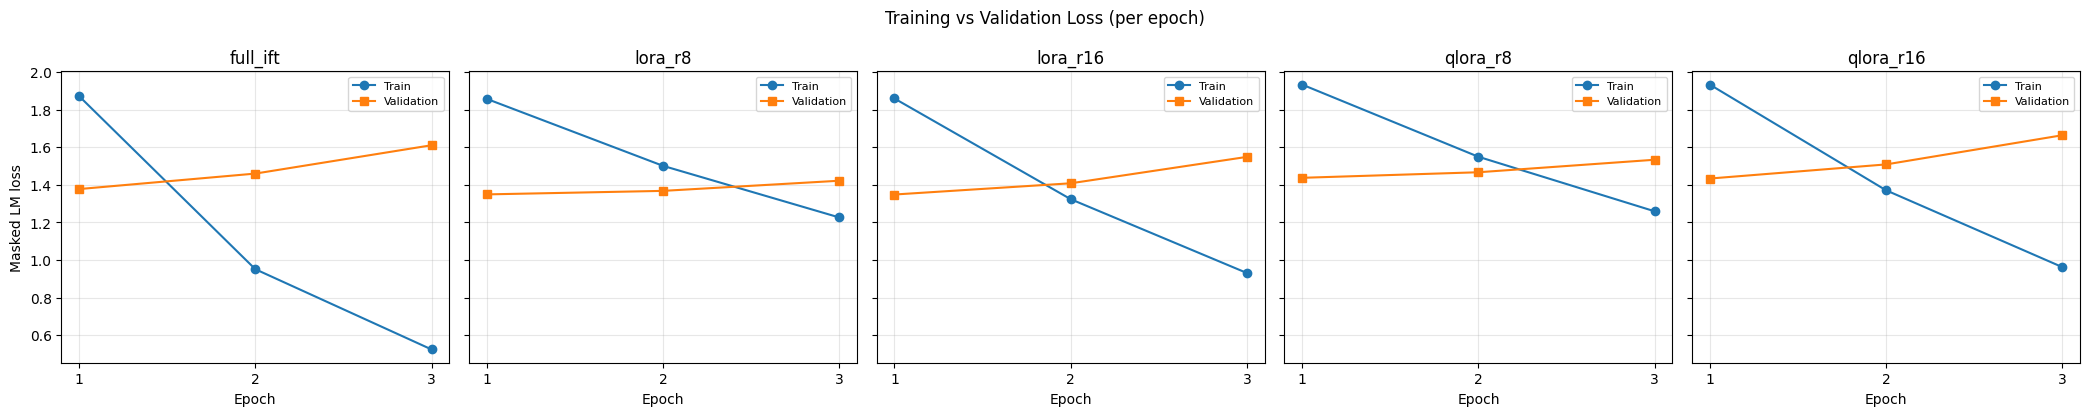

In [23]:
# ============================================================
#  Step 10: Plots — Train vs Validation Loss (per epoch)
# ============================================================

# Gather every run's history under one name -> hist mapping.
plot_hist = {"full_ift": full_hist}
for method, runs in [("lora", lora_runs), ("qlora", qlora_runs)]:
    for rank, run in runs.items():
        plot_hist[f"{method}_r{rank}"] = run["hist"]

n = len(plot_hist)
fig, axes = plt.subplots(1, n, figsize=(4.2 * n, 4.2), sharey=True)
if n == 1:
    axes = [axes]

for ax, (name, hist) in zip(axes, plot_hist.items()):
    epochs = range(1, len(hist["train_loss"]) + 1)
    ax.plot(epochs, hist["train_loss"], "o-", label="Train")
    ax.plot(epochs, hist["val_loss"],   "s-", label="Validation")
    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_xticks(list(epochs))
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_ylabel("Masked LM loss")
plt.suptitle("Training vs Validation Loss (per epoch)")
plt.tight_layout()
plt.show()

### ✍️ Step 10 Reflection  <font color="red">**[2 marks]**</font>

**[Your Answer]** must cover:
- Which method converged fastest and to the lowest validation loss, and whether any run shows signs of **overfitting** (validation rising while training keeps falling). <font color="red">**[1 marks]**</font>
- Whether a lower *training* loss reliably predicted better *test* answers back in Step 9 — and what that tells you. <font color="red">**[1 marks]**</font>

*Cite the curves and the Step 9 numbers.*

<font color="green">ANSWER:

1) All five models achieved their lowest validation loss at epoch 1, with LoRA r=16 achieving the lowest (1.3483), closely followed by LoRA r=8 (1.3490). Full IFT showed the fastest reduction in training loss (1.8717 → 0.5248). All runs showed overfitting, as validation loss increased while training loss continued decreasing. For example, Full IFT validation loss rose from 1.3773 to 1.6103.

2) Lower training loss did not reliably predict better test answers. Full IFT achieved the lowest final training loss (0.5248) and highest test scores (ROUGE-L 0.2831, BERTScore-F1 0.8905), but LoRA r=16 had lower training loss than LoRA r=8 (0.9310 vs. 1.2264) while producing a worse ROUGE-L (0.2673 vs. 0.2738). This shows that training loss measures fitting the training examples, whereas test metrics better reflect generalization to unseen questions.
---------------------
---------------------
---------------------
</font>

## <font color="blue"><b>Step 11: Error Analysis</b></font>  <font color="red">**[8 marks]**</font>

Numbers alone don't tell you *how* a model is wrong. Take the best run by **ROUGE-L**, print a few of its generated answers next to the references, and back that up with a quantitative summary of the failure modes: predicted-vs-reference length, the length ratio (a quick proxy for rambling or truncation), and counts of empty / much-shorter / much-longer generations.

**Marks:** code <font color="red">**[4 marks]**</font> — select the best run by ROUGE-L, show sample generations vs references, and compute the length-ratio + failure-mode summary; reflection <font color="red">**[4 marks]**</font> — see below.

In [24]:
# ============================================================
#  Step 11: Error Analysis
# ============================================================

# Pick the best run by ROUGE-L.
best = max(results, key=lambda k: results[k]["rougeL"])
print(f"Best model by ROUGE-L: {best}  "
      f"(ROUGE-L={results[best]['rougeL']}, BERTScore-F1={results[best]['bertscore_f1']})")
print("=" * 76)

# Show a few generated answers vs the references.
for i in range(3):
    print(f"\nExample {i + 1}")
    print("-" * 76)

    print("Instruction:")
    print(test_df.iloc[i]["instruction"])

    input_text = test_df.iloc[i]["input"]
    if pd.notna(input_text) and str(input_text).strip():
        print("\nInput:")
        print(input_text)

    print("\nReference Answer:")
    print(test_refs[i])

    print("\nGenerated Answer:")
    print(preds_store[best][i])

    print("-" * 76)


Best model by ROUGE-L: full_ift  (ROUGE-L=0.2830863326764514, BERTScore-F1=0.8905271410942077)

Example 1
----------------------------------------------------------------------------
Instruction:
Name two types of unsupervised learning.

Reference Answer:
The two types of unsupervised learning are clustering and association rule learning.

Generated Answer:
Unsupervised learning is used to identify patterns in data that do not have any labels attached to them. It can be used to find hidden structures in data such as clustering, classification, and association rules.
----------------------------------------------------------------------------

Example 2
----------------------------------------------------------------------------
Instruction:
Create a sentence using the given verb and adjective.

Input:
Verb: glow
Adjective: luminous

Reference Answer:
The sky was illuminated with a luminous glow.

Generated Answer:
The glowing light illuminated the darkness.
----------------------------

In [27]:
# ---- Quantitative summary of the errors ----

# Get predictions and references for the best model
best_preds = preds_store[best]
best_refs = test_refs[:len(best_preds)]

# Calculate token lengths using the same tokenizer
pred_lens = np.array([
    len(tokenizer.encode(p, add_special_tokens=False))
    for p in best_preds
])

ref_lens = np.array([
    len(tokenizer.encode(r, add_special_tokens=False))
    for r in best_refs
])

# Calculate prediction-to-reference length ratio
# Avoid division by zero for empty references
len_ratio = pred_lens / np.maximum(ref_lens, 1)

# Count failure modes
empty = int(np.sum(pred_lens == 0))
too_short = int(np.sum(len_ratio < 0.5))
too_long = int(np.sum(len_ratio > 2.0))


print(f"\nError summary for '{best}'  (over {len(best_preds)} test prompts)")
print("-" * 60)
print(f"Avg predicted length : {pred_lens.mean():.0f} tokens")
print(f"Avg reference length : {ref_lens.mean():.0f} tokens")
print(f"Length ratio (pred/ref): mean={len_ratio.mean():.2f}  median={np.median(len_ratio):.2f}")
print(f"Empty generations      : {empty}")
print(f"Much shorter (<0.5x)   : {too_short}")
print(f"Much longer  (>2.0x)   : {too_long}")


Error summary for 'full_ift'  (over 30 test prompts)
------------------------------------------------------------
Avg predicted length : 63 tokens
Avg reference length : 46 tokens
Length ratio (pred/ref): mean=1.89  median=1.13
Empty generations      : 0
Much shorter (<0.5x)   : 1
Much longer  (>2.0x)   : 8


### ✍️ Step 11 Reflection  <font color="red">**[4 marks]**</font>

**[Your Answer]** must cover:
- One recurring way the model's answers differ from the references — length, specificity, hedging, or incorrect arithmetic, invented financial facts, missing assumptions, or unsupported certainty — with a concrete example from the samples. <font color="red">**[2 marks]**</font>
- What the length-ratio and failure counts reveal about the model's behaviour (rambling, truncation, empty generations). <font color="red">**[1 marks]**</font>
- One concrete change you would try to reduce these errors (e.g. more epochs, higher rank, longer `MAX_LEN`, or different decoding settings). <font color="red">**[1 marks]**</font>

*Cite the samples and the summary numbers your run produced.*

<font color="green">ANSWER:

1) The Full IFT model tends to generate longer, less specific answers than the references. For example, in the unsupervised-learning question, it correctly mentioned clustering and association rules but unnecessarily included classification, which is generally supervised learning. In the sentence-generation example, it omitted the requested adjective "luminous," showing an instruction-following error.

2)  Across 30 test prompts, predictions averaged 63 tokens versus 46 reference tokens, with a mean length ratio of 1.89 and median of 1.13. There were 8 excessively long answers (>2×), 1 much-shorter answer (<0.5×), and 0 empty generations. This indicates a tendency toward verbosity rather than truncation or failure to generate.

3) I would try reducing max_new_tokens from 200 to 100 and adding an instruction to provide concise, direct answers. This could reduce unnecessary explanations and overly long responses, although it would need testing to ensure that longer financial answers are not truncated.
---------------------
---------------------
---------------------
</font>

## <font color="blue"><b>Step 12: Parameter Analysis</b></font>  <font color="red">**[6 marks]**</font>

Bring everything together into the cost–quality picture. Build one comparison table across all five runs — **quality** (ROUGE-L, BERTScore-F1) against **cost** (% trainable parameters, peak GPU memory, training time) — then draw the supporting charts: quality bars with peak memory annotated, and a trainable-% bar chart that makes the full-IFT-vs-adapter gap obvious.

**Marks:** code <font color="red">**[4 marks]**</font> — the comparison table over all runs and the quality + trainable-% charts; reflection <font color="red">**[2 marks]**</font> — see below.

In [28]:
# ============================================================
#  Step 12: Parameter Analysis
# ============================================================

# ---- Comparison table: quality vs cost across every run ----

comparison_df = pd.DataFrame.from_dict(results, orient="index")

# Arrange columns for quality vs cost comparison
comparison_df = comparison_df[
    [
        "rougeL",
        "bertscore_f1",
        "pct_trainable",
        "peak_mem_gb",
        "train_time_s"
    ]
]

# Rename columns for readability
comparison_df.columns = [
    "ROUGE-L",
    "BERTScore-F1",
    "Trainable (%)",
    "Peak Memory (GB)",
    "Training Time (s)"
]

# Rename model labels
comparison_df.index = [
    name.replace("full_ift", "Full IFT")
        .replace("lora_r", "LoRA r=")
        .replace("qlora_r", "QLoRA r=")
    for name in comparison_df.index
]

comparison_df.index.name = "Method"

print("Quality vs Cost Comparison — All Five Models")
display(comparison_df.round(4))


Quality vs Cost Comparison — All Five Models


,ROUGE-L,BERTScore-F1,Trainable (%),Peak Memory (GB),Training Time (s)
Method,,,,,
Full IFT,0.2831,0.8905,100.00,9.92,249.5
LoRA r=8,0.2738,0.8847,0.88,4.01,185.4
LoRA r=16,0.2673,0.8883,1.75,4.06,186.4
qLoRA r=8,0.2661,0.8854,1.38,2.77,130.1
qLoRA r=16,0.2689,0.8861,2.72,2.82,129.2


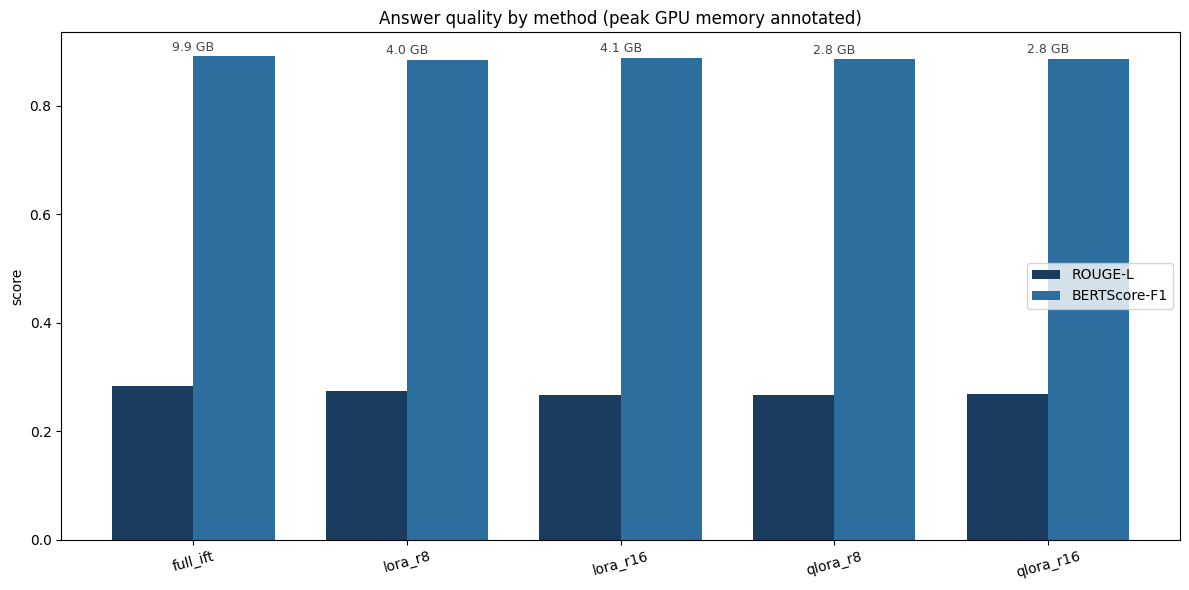

In [29]:
# ---- Quality chart with peak memory annotated ----
names   = list(results.keys())
rougeLs = [results[m]["rougeL"] for m in names]
berts   = [results[m]["bertscore_f1"] for m in names]
x = np.arange(len(names)); w = 0.38

fig, ax = plt.subplots(figsize=(1.8 * len(names) + 3, 6))
ax.bar(x - w/2, rougeLs, w, label="ROUGE-L", color="#1a3c5e")
ax.bar(x + w/2, berts,   w, label="BERTScore-F1", color="#2c6e9e")
ax.set_xticks(x); ax.set_xticklabels(names, rotation=15)
ax.set_ylabel("score")
ax.set_title("Answer quality by method (peak GPU memory annotated)")

for i, m in enumerate(names):
    mem = results[m]["peak_mem_gb"]
    ax.text(i, max(rougeLs[i], berts[i]) + 0.01,
            f"{mem:.1f} GB" if mem is not None else "-",
            ha="center", fontsize=9, color="#444")

ax.legend(); plt.tight_layout(); plt.show()

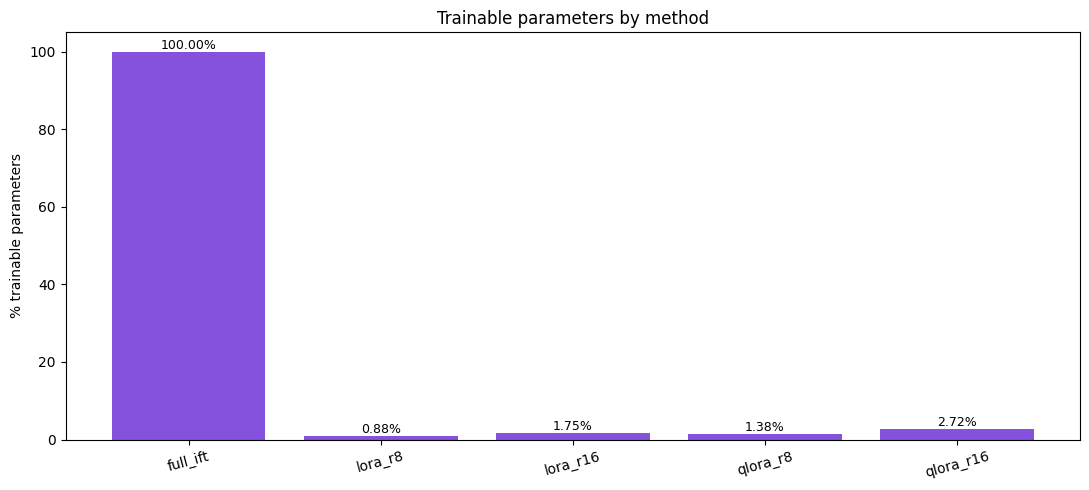

In [30]:
# ---- Trainable-parameters comparison (the LoRA/QLoRA story) ----
fig, ax = plt.subplots(figsize=(1.6 * len(names) + 3, 5))
pcts = [results[m]["pct_trainable"] for m in names]
bars = ax.bar(names, pcts, color="#8452dd")
ax.set_ylabel("% trainable parameters")
ax.set_title("Trainable parameters by method")
ax.set_xticklabels(names, rotation=15)
for b, p in zip(bars, pcts):
    ax.text(b.get_x() + b.get_width()/2, p, f"{p:.2f}%", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

### ✍️ Step 12 Reflection  <font color="red">**[2 marks]**</font>

**[Your Answer]** must cover:
- Which method gives the best **balance** of quality, trainable-%, memory, and training time for a free T4 — not simply the highest score — citing the comparison table. <font color="red">**[1 marks]**</font>
- How **rank** (8 vs 16) and **quantisation** (LoRA vs QLoRA) each traded answer quality against cost. <font color="red">**[1 marks]**</font>

*Cite the actual numbers from your comparison table.*

<font color="green">ANSWER:

1)  I would choose QLoRA r=8 for a free T4 GPU because it achieved reasonable quality (ROUGE-L 0.2661, BERTScore-F1 0.8854) while using only 2.77 GB GPU memory, 1.38% reported trainable parameters, and 130.1 seconds training time. Compared with Full IFT (ROUGE-L 0.2831, BERTScore-F1 0.8905, 9.92 GB, 249.5 seconds), it saved approximately 72% memory and 48% training time, with a relatively small reduction in measured answer quality.

2) Increasing LoRA rank from 8 to 16 doubled trainable parameters (0.88% to 1.75%) but slightly reduced ROUGE-L (0.2738 to 0.2673), while BERTScore-F1 improved (0.8847 to 0.8883). QLoRA r=16 slightly improved both quality metrics over QLoRA r=8 but increased reported trainable parameters (1.38% to 2.72%). Quantization reduced memory from 4.01 GB to 2.77 GB at r=8, with a small quality trade-off, making QLoRA more suitable for memory-constrained GPUs.

---------------------
---------------------
---------------------
</font>

In [31]:
# ----------------------END of the SOLUTION-----------------